# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Rivera, Kyle Florian
- _Student No._: 2024-16197
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report Figure


1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

![Relative Errors](errors.png)
Figure 1. Absolute error of various integration techniques relative to `scipy.integrate.quad` evaluation

![Monte Carlo Hits](montecarlo.png)
Figure 2. Monte Carlo integration of three functions.

### Report Discussion 

1. As we increase the number of points, the absolute error (relative to `scipy.interpolate.quad`) decreases. However, as seen in the figure, Monte Carlo integration 

2. We arrive at the value for Monte Carlo simulation
Moreover, unlike Newton-Cotes methods, Monte Carlo integration bodes well on higher dimensional integrals.

- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?
  
### Other comments
- No comment

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)

Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand. Test your functions on the following curves and bounds:

1. $ y = \sqrt{9-4x^2}, x=0, x=3/2 $
2. $ y = -x^2 + 1, x=-2, x=2 $
3. $ y = \sqrt{x}\cos{x}, x=0, x=\pi $

Check your answers (of the integral) with `scipy.integrate.quad`

> We start by defining the functions that we will evaluate and importing the libraries that we will use

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=1010)

In [3]:
def func1(x):
    return np.sqrt(9 - (4*x**2))

def func2(x):
    return -x**2 + 1

def func3(x):
    return np.cos(x) * np.sqrt(x)

> In order to tidy up our code down the line, I have decided to implement the four integration methods using object-oriented programming. A parent class `Setup` was created, containing the algorithms for calculating the integral

In [4]:
class Setup: # we setup this parent class as the other integration proccesses use the same logic 
    def __init__(self, function, start, end, points):
        self.function = function
        self.start = start
        self.end = end
        self.xs = np.linspace(start, end, points)
        self.ys = self.function(self.xs)
        self.dx = (end-start)/(points-1)

    def calculate(self):
        return self.weights*self.function(self.xs)
        
    def signed(self, show=False):
        signed_area = np.sum(self.calculate())
        if show:
            print(f"Signed Area: {signed_area}")
        return signed_area
    
    def total(self, show=False):
        total_area = np.sum(np.abs(self.calculate()))
        if show:
            print(f"Total Area: {total_area}")
        return total_area

class Trapezoid(Setup):
    def __init__(self, function, start, end, points):
        super().__init__(function, start, end, points)
        coefficients = np.ones(points); coefficients[0], coefficients[-1] = 0.5, 0.5
        self.weights = self.dx*coefficients
    
class SimpsonThird(Setup):
    def __init__(self, function, start, end, points):
        if points % 2 != 1:
            raise ValueError("must be an odd number of points")
        super().__init__(function, start, end, points)
        coefficients = [4 if i%2 == 1 else 2 for i in range(points)] # set odd indices to 4, set even indeces to 2
        coefficients[0], coefficients[-1] = 1, 1
        self.weights = (self.dx/3)*np.array(coefficients)
    
class SimpsonEight(Setup):
    def __init__(self, function, start, end, points):
        if (points-1) % 3 != 0:
            raise ValueError("The slices (points-1) must be a multiple of three")
        super().__init__(function, start, end, points)
        coefficients = [2 if i%3 == 0 else 3 for i in range(points)] # set every third indices to 2, otherwise set it as 3
        coefficients[0], coefficients[-1] = 1, 1
        self.weights = (3*self.dx/8)*np.array(coefficients)

class MonteCarlo(Setup):
    def __init__(self, function, start, end, points):
        super().__init__(function, start, end, points)
        self.xr = rng.uniform(start, end, points)

        # we want to find the max of the orig func
        ys_min, ys_max = min(np.min(self.ys), 0), max(np.max(self.ys), 0)
        
        # evaluate f at random points
        self.fxr = self.function(self.xr)
        self.yr = rng.uniform(ys_min, ys_max, points) # we obtain random y coordinates within the limits of the function

        box_area = (ys_max - ys_min) * (end - start) # we find the total area 

        # finding if the dots are within the curve and below/above axis
        above = np.where((0 <= self.yr) & (self.yr <= self.fxr), 1, 0) # set positive if within bounds, 0 otherwise
        below = np.where((self.fxr <= self.yr) & (self.yr < 0), -1, 0) # set negative if within bounds, 0 otherwise
        self.hits = above + below
        
        self.weights = box_area / points

    def calculate(self): # we redefine the way we calculate since we are using monte carlo hits
        return self.weights*self.hits
        

> We can now evaluate the integral of each function.

In [5]:
functions = [func1, func2, func3]
bounds = [[0, 1.5], [-2, 2], [0, np.pi]]
signed_result = []
total_result = []

for func, bound in zip(functions, bounds):
    t = Trapezoid(func, bound[0], bound[1], 100000)
    st = SimpsonThird(func, bound[0], bound[1], 100001)
    se = SimpsonEight(func, bound[0], bound[1], 1000000)
    m = MonteCarlo(func, bound[0], bound[1], 10000000)
    
    signed_result.append([t.signed(), st.signed(), se.signed(), m.signed()])
    total_result.append([t.total(), st.total(), se.total(), m.total()])

> To keep our results neat, let us use pandas dataframes to tabulate it.

In [6]:
import pandas as pd

In [7]:
titles = ['Trapezoid','Simpson Thirds','Simpson Eights','Monte Carlo']
func_titles = [r'$\sqrt{9 - 4x^2}$', r'$-x^2 + 1$', r'$\sqrt{x} \cos(x)$'] 

df_signed = pd.DataFrame(
                        signed_result,
                        columns = titles,
                        index = func_titles
                        )
print("Signed Area (Integral): \n", df_signed)
print()
df_total = pd.DataFrame(
                        total_result,
                        columns = titles,
                        index = func_titles
                        )
print("Total Area Bounded: \n", df_total)

Signed Area (Integral): 
                     Trapezoid  Simpson Thirds  Simpson Eights  Monte Carlo
$\sqrt{9 - 4x^2}$    3.534292        3.534292        3.534292     3.534576
$-x^2 + 1$          -1.333333       -1.333333       -1.333333    -1.335506
$\sqrt{x} \cos(x)$  -0.894832       -0.894831       -0.894831    -0.895530

Total Area Bounded: 
                     Trapezoid  Simpson Thirds  Simpson Eights  Monte Carlo
$\sqrt{9 - 4x^2}$    3.534292        3.534292        3.534292     3.534576
$-x^2 + 1$           4.000000        4.000000        4.000000     4.002594
$\sqrt{x} \cos(x)$   2.302907        2.302907        2.302907     2.303508


> Now, lets plot the Monte Carlo hits

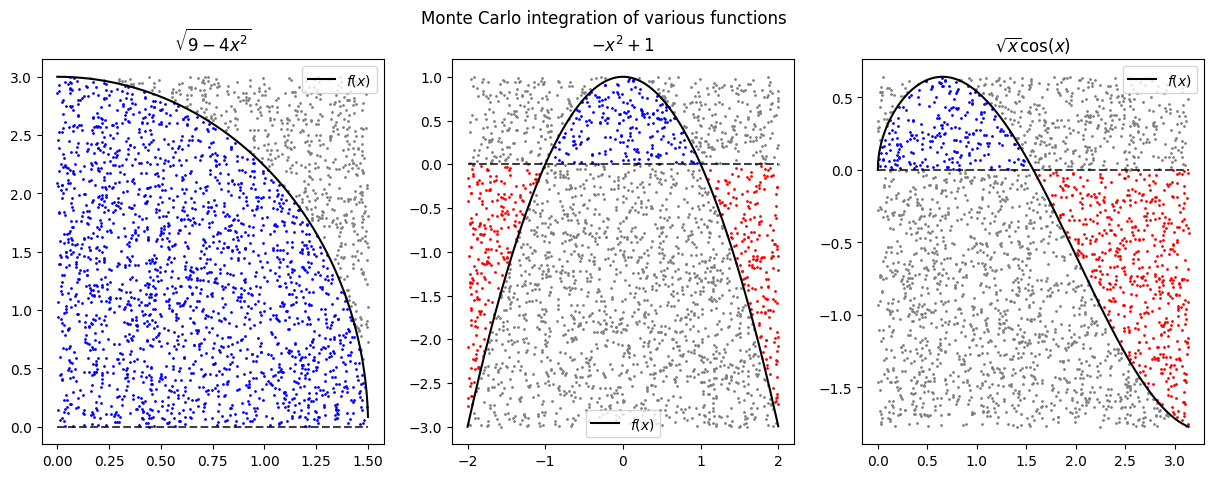

In [8]:
points = 10000000 # how many points do we actually calculate
resolution = 2500 # how many points in graph (for visualization)
interval = points // resolution

fig, axs = plt.subplots(1, 3, figsize=(15,5))

for func, func_title, bound, ax in zip(functions, func_titles, bounds, axs):
    m = MonteCarlo(func, bound[0], bound[1], points)
    
    above = m.hits == 1
    below = m.hits == -1
    miss = m.hits == 0
    
    states = [above, below, miss]
    colors = ['blue', 'red', 'grey']
    
    for state, color in zip(states, colors):
        ax.scatter(m.xr[state][::interval], m.yr[state][::interval], s=1, c=color)
        
    ax.plot(m.xs[::interval], m.ys[::interval], c='black', label='$f(x)$')
    ax.plot(np.linspace(bound[0], bound[1], 1000), np.zeros(1000), c='black', ls='--', alpha=0.75)
    ax.legend()
    ax.set_title(func_title)

plt.suptitle('Monte Carlo integration of various functions')
plt.savefig('montecarlo.png', dpi=600)
plt.show()

> Now, lets plot the errors of each integration methods (relative to `scipy.integrate.quad`. Note that we only compare the signed area since that's what scipy provides

In [9]:
from scipy import integrate

In [10]:
points = np.logspace(1, 7, 7, dtype=int)
errors = {func_title: [] for func_title in func_titles} # we create a dict to put the error values

for func, func_title, bound in zip(functions, func_titles, bounds):
    for point in points:
        true = integrate.quad(func, bound[0], bound[1])[0] # we take [0] i.e. first element since quad outputs a tuple of value and error
        t = Trapezoid(func, bound[0], bound[1], point)
        st = SimpsonThird(func, bound[0], bound[1], point+1) # plus 1 so it is odd
        se = SimpsonEight(func, bound[0], bound[1], point)
        m = MonteCarlo(func, bound[0], bound[1], point)
        
        errors[func_title].append([abs(true - method.signed()) for method in [t, st, se, m]]) 

np.transpose(errors); # we put it in proper dict form and so it is easier to read

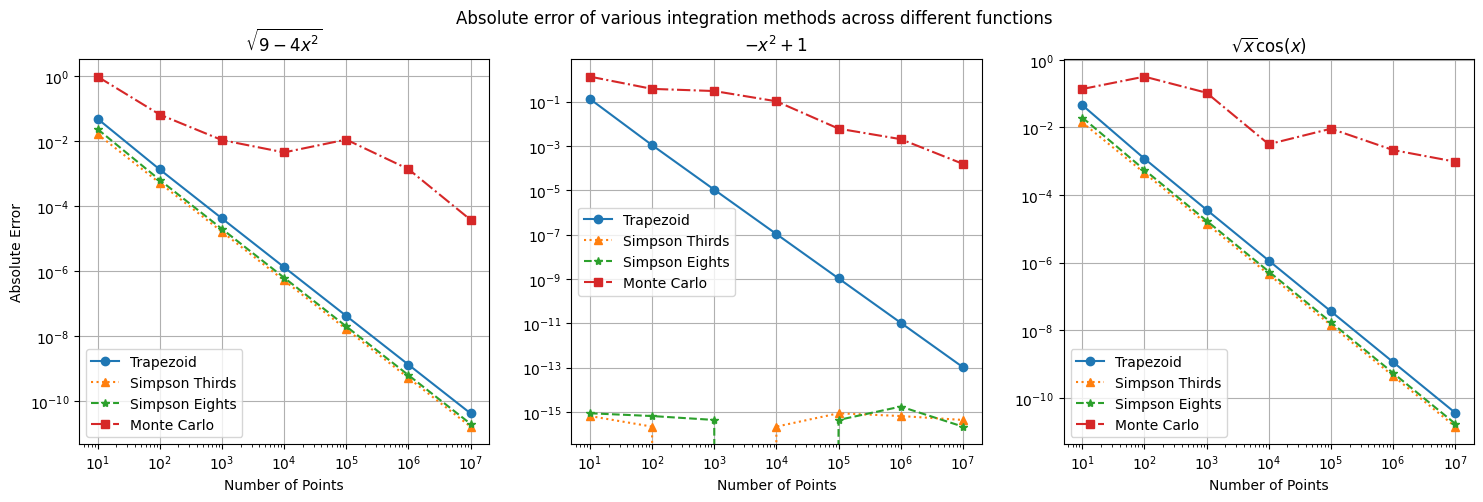

In [11]:
markers = ['o', '^', '*', 's']
linestyle_str = [
     ('solid'),      # Same as (0, ()) or '-'
     ('dotted'),    # Same as ':'
     ('dashed'),    # Same as '--'
     ('dashdot')]  # Same as '-.'

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

for func_title, ax in zip(func_titles, axs):
    error_func = np.array(errors[func_title])
    for i, (title, marker, ls) in enumerate(zip(titles, markers, linestyle_str)):
        ax.loglog(points, error_func[:, i], label=title, marker=marker, ls=ls)
    ax.grid(True)
    ax.legend()
    ax.set_title(func_title)
    ax.set_xlabel("Number of Points")

axs[0].set_ylabel("Absolute Error")
plt.suptitle("Absolute error of various integration methods across different functions")
plt.savefig("errors.png", dpi=600)
plt.show()

#### Problem 1 code summary

The signed area and area bounded by the curve and the axis were found using four different numerical integration techniques (Trapezoidal, Simpson's, Simpson's Three-Eights, Monte Carlo). Object oriented programming was used in order to tidy up variable assignments and efficiently evaluate the integral by using a shared parent class. Afterward, the absolute error of the signed area (relative to `scipy.integrate.quad`) was plotted as the number of points were increased.

---